In [1]:
# Step 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

# Display all columns
pd.set_option('display.max_columns', None)

# Set graph style
plt.style.use('seaborn-v0_8')

In [2]:
# Step 2: Load CSV Dataset

df = pd.read_csv("customer_shopping_data.csv")

print("CSV Dataset Loaded Successfully!")
print(df.head())

CSV Dataset Loaded Successfully!
  invoice_no customer_id  gender  age  category  quantity    price  \
0    I138884     C241288  Female   28  Clothing         5  1500.40   
1    I317333     C111565    Male   21     Shoes         3  1800.51   
2    I127801     C266599    Male   20  Clothing         1   300.08   
3    I173702     C988172  Female   66     Shoes         5  3000.85   
4    I337046     C189076  Female   53     Books         4    60.60   

  payment_method invoice_date   shopping_mall  
0    Credit Card     5/8/2022          Kanyon  
1     Debit Card   12/12/2021  Forum Istanbul  
2           Cash    9/11/2021       Metrocity  
3    Credit Card   16/05/2021    Metropol AVM  
4           Cash   24/10/2021          Kanyon  


In [3]:
# Step 5: Combine all available datasets

datasets = [df]

if 'excel_df' in globals():
    datasets.append(excel_df)

if 'db_df' in globals():
    datasets.append(db_df)

df = pd.concat(datasets, ignore_index=True)

print("Combined Dataset:")
print(df.head())
print("Total Records:", len(df))

Combined Dataset:
  invoice_no customer_id  gender  age  category  quantity    price  \
0    I138884     C241288  Female   28  Clothing         5  1500.40   
1    I317333     C111565    Male   21     Shoes         3  1800.51   
2    I127801     C266599    Male   20  Clothing         1   300.08   
3    I173702     C988172  Female   66     Shoes         5  3000.85   
4    I337046     C189076  Female   53     Books         4    60.60   

  payment_method invoice_date   shopping_mall  
0    Credit Card     5/8/2022          Kanyon  
1     Debit Card   12/12/2021  Forum Istanbul  
2           Cash    9/11/2021       Metrocity  
3    Credit Card   16/05/2021    Metropol AVM  
4           Cash   24/10/2021          Kanyon  
Total Records: 99457


In [4]:
# Step 6: Display and Inspect Dataset

print("First 5 Records:")
print(df.head())

print("\nLast 5 Records:")
print(df.tail())

print("\nDataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nStatistical Description:")
print(df.describe())

First 5 Records:
  invoice_no customer_id  gender  age  category  quantity    price  \
0    I138884     C241288  Female   28  Clothing         5  1500.40   
1    I317333     C111565    Male   21     Shoes         3  1800.51   
2    I127801     C266599    Male   20  Clothing         1   300.08   
3    I173702     C988172  Female   66     Shoes         5  3000.85   
4    I337046     C189076  Female   53     Books         4    60.60   

  payment_method invoice_date   shopping_mall  
0    Credit Card     5/8/2022          Kanyon  
1     Debit Card   12/12/2021  Forum Istanbul  
2           Cash    9/11/2021       Metrocity  
3    Credit Card   16/05/2021    Metropol AVM  
4           Cash   24/10/2021          Kanyon  

Last 5 Records:
      invoice_no customer_id  gender  age         category  quantity    price  \
99452    I219422     C441542  Female   45         Souvenir         5    58.65   
99453    I325143     C569580    Male   27  Food & Beverage         2    10.46   
99454    I8240

In [5]:
# Step 7: Check Missing Values and Duplicates

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
invoice_no        0
customer_id       0
gender            0
age               0
category          0
quantity          0
price             0
payment_method    0
invoice_date      0
shopping_mall     0
dtype: int64

Duplicate Records:
0


In [6]:
# Step 8: Clean Dataset

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Fill missing numerical values with 0
num_cols = df.select_dtypes(include=np.number).columns
df[num_cols] = df[num_cols].fillna(0)

# Fill missing text values with Unknown
cat_cols = df.select_dtypes(include='object').columns
df[cat_cols] = df[cat_cols].fillna('Unknown')

print("Dataset Cleaned Successfully!")
print(df.isnull().sum())

Dataset Cleaned Successfully!
invoice_no        0
customer_id       0
gender            0
age               0
category          0
quantity          0
price             0
payment_method    0
invoice_date      0
shopping_mall     0
dtype: int64


C:\Users\rudra\AppData\Local\Temp\ipykernel_11936\1865494467.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns


In [7]:
# Step 9: Standardize Column Names

df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# Convert price into numeric format
df['price'] = pd.to_numeric(df['price'], errors='coerce').fillna(0)

print("Standardized Columns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

Standardized Columns:
Index(['invoice_no', 'customer_id', 'gender', 'age', 'category', 'quantity',
       'price', 'payment_method', 'invoice_date', 'shopping_mall'],
      dtype='str')

Data Types:
invoice_no            str
customer_id           str
gender                str
age                 int64
category              str
quantity            int64
price             float64
payment_method        str
invoice_date          str
shopping_mall         str
dtype: object


In [8]:
# Step 10: Calculate Total Sales

df['TotalSales'] = df['price']

print("Total Sales:", df['TotalSales'].sum())

Total Sales: 68551365.91


In [9]:
# Step 11: Sales by Shopping Mall

region_counts = df['shopping_mall'].value_counts()

region_sales = df.groupby('shopping_mall')['TotalSales'].sum()
region_sales = region_sales.sort_values(ascending=False)

print("Number of Transactions:")
print(region_counts)

print("\nSales by Shopping Mall:")
print(region_sales)

Number of Transactions:
shopping_mall
Mall of Istanbul     19943
Kanyon               19823
Metrocity            15011
Metropol AVM         10161
Istinye Park          9781
Zorlu Center          5075
Cevahir AVM           4991
Forum Istanbul        4947
Viaport Outlet        4914
Emaar Square Mall     4811
Name: count, dtype: int64

Sales by Shopping Mall:
shopping_mall
Mall of Istanbul     13851737.62
Kanyon               13710755.24
Metrocity            10249980.07
Metropol AVM          6937992.99
Istinye Park          6717077.54
Zorlu Center          3509649.02
Cevahir AVM           3433671.84
Viaport Outlet        3414019.46
Emaar Square Mall     3390408.31
Forum Istanbul        3336073.82
Name: TotalSales, dtype: float64


In [10]:
# Step 12: Sales by Product Category

category_counts = df['category'].value_counts()

category_sales = df.groupby('category')['TotalSales'].sum()
category_sales = category_sales.sort_values(ascending=False)

print("Transactions by Category:")
print(category_counts)

print("\nSales by Category:")
print(category_sales)

Transactions by Category:
category
Clothing           34487
Cosmetics          15097
Food & Beverage    14776
Toys               10087
Shoes              10034
Souvenir            4999
Technology          4996
Books               4981
Name: count, dtype: int64

Sales by Category:
category
Clothing           31075684.64
Shoes              18135336.89
Technology         15772050.00
Cosmetics           1848606.90
Toys                1086704.64
Food & Beverage      231568.71
Books                226977.30
Souvenir             174436.83
Name: TotalSales, dtype: float64


In [11]:
# Step 13: Shopping Mall vs Product Category

combined_sales = df.pivot_table(
    index='shopping_mall',
    columns='category',
    values='TotalSales',
    aggfunc='sum',
    fill_value=0
)

print("Combined Sales:")
print(combined_sales)

Combined Sales:
category              Books    Clothing  Cosmetics  Food & Beverage  \
shopping_mall                                                         
Cevahir AVM        11998.80  1554414.40   88394.84         11992.39   
Emaar Square Mall  11059.50  1511803.04   92379.52         11030.07   
Forum Istanbul     11453.40  1572119.12   95225.72         10836.56   
Istinye Park       20725.20  3050313.20  178741.36         23419.94   
Kanyon             44980.35  6155541.04  372242.30         45474.85   
Mall of Istanbul   46949.85  6245565.04  373787.38         46431.94   
Metrocity          34405.65  4719958.32  272422.00         35375.72   
Metropol AVM       22240.20  3166444.16  185775.54         23984.78   
Viaport Outlet     10908.00  1530708.08   92664.14         11432.78   
Zorlu Center       12256.35  1568818.24   96974.10         11589.68   

category                Shoes  Souvenir  Technology       Toys  
shopping_mall                                                   
C

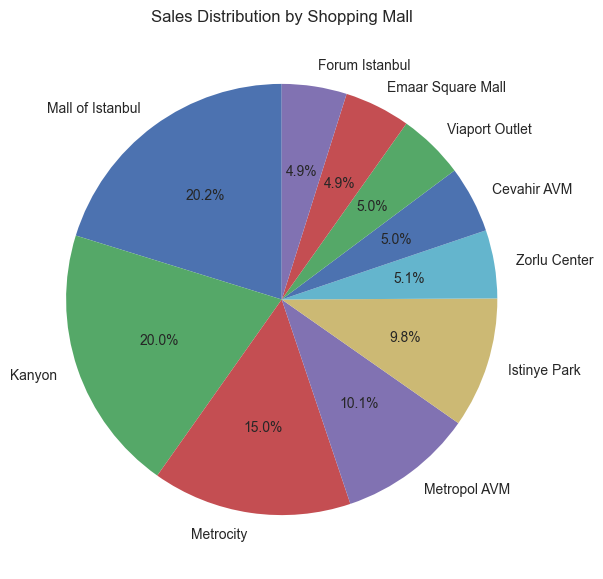

In [12]:
# Step 14: Pie Chart

plt.figure(figsize=(7, 7))

plt.pie(
    region_sales,
    labels=region_sales.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Sales Distribution by Shopping Mall")
plt.show()

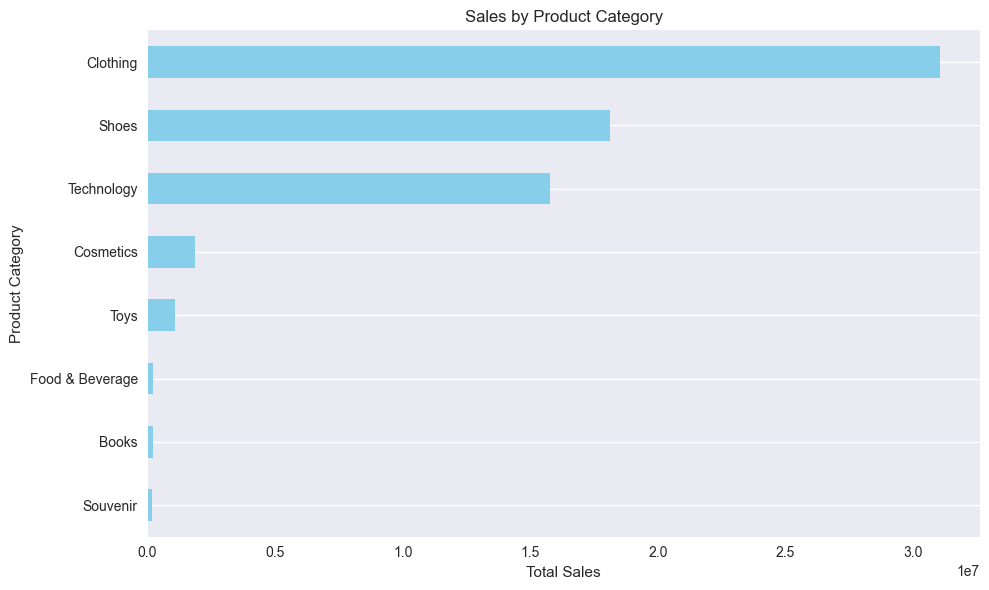

In [13]:
# Step 15: Horizontal Bar Chart

category_sales_sorted = category_sales.sort_values(ascending=True)

plt.figure(figsize=(10, 6))

category_sales_sorted.plot(kind='barh', color='skyblue')

plt.xlabel("Total Sales")
plt.ylabel("Product Category")
plt.title("Sales by Product Category")
plt.grid(axis='x')
plt.tight_layout()
plt.show()

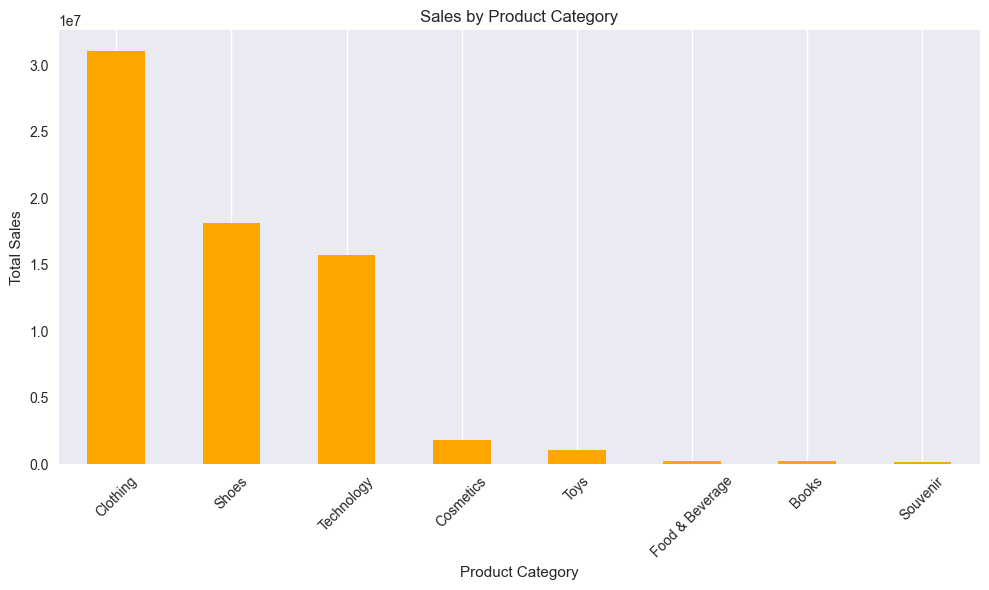

In [14]:
# Step 16: Vertical Bar Chart

plt.figure(figsize=(10, 6))

category_sales.plot(kind='bar', color='orange')

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

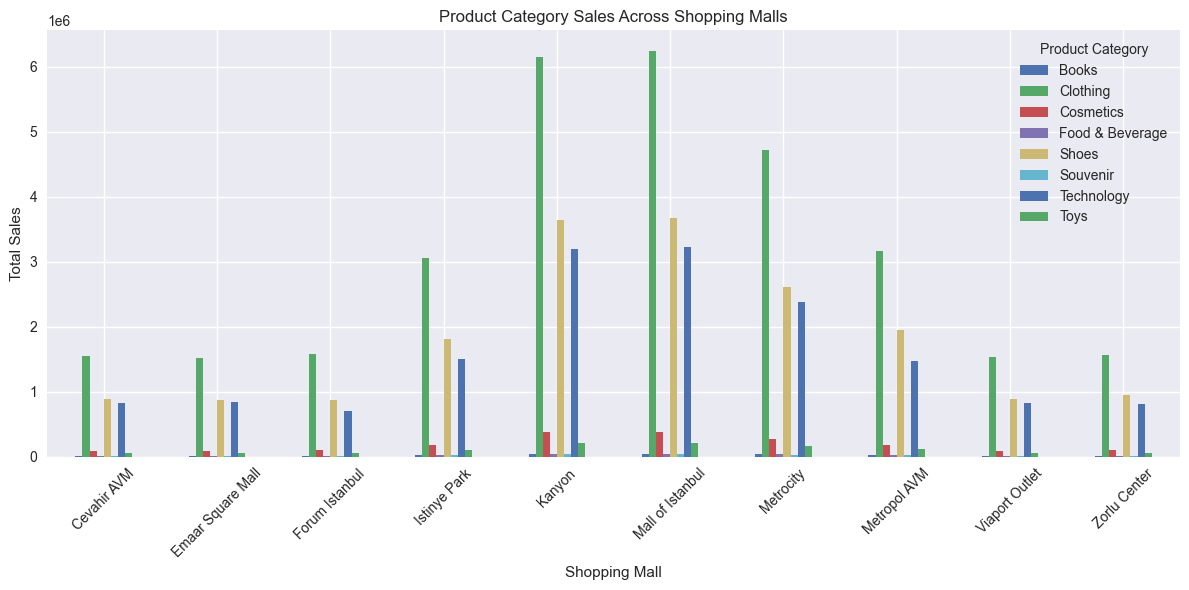

In [15]:
# Step 17: Grouped Bar Chart

combined_sales.plot(kind='bar', figsize=(12, 6))

plt.title("Product Category Sales Across Shopping Malls")
plt.xlabel("Shopping Mall")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.legend(title="Product Category")
plt.tight_layout()
plt.show()

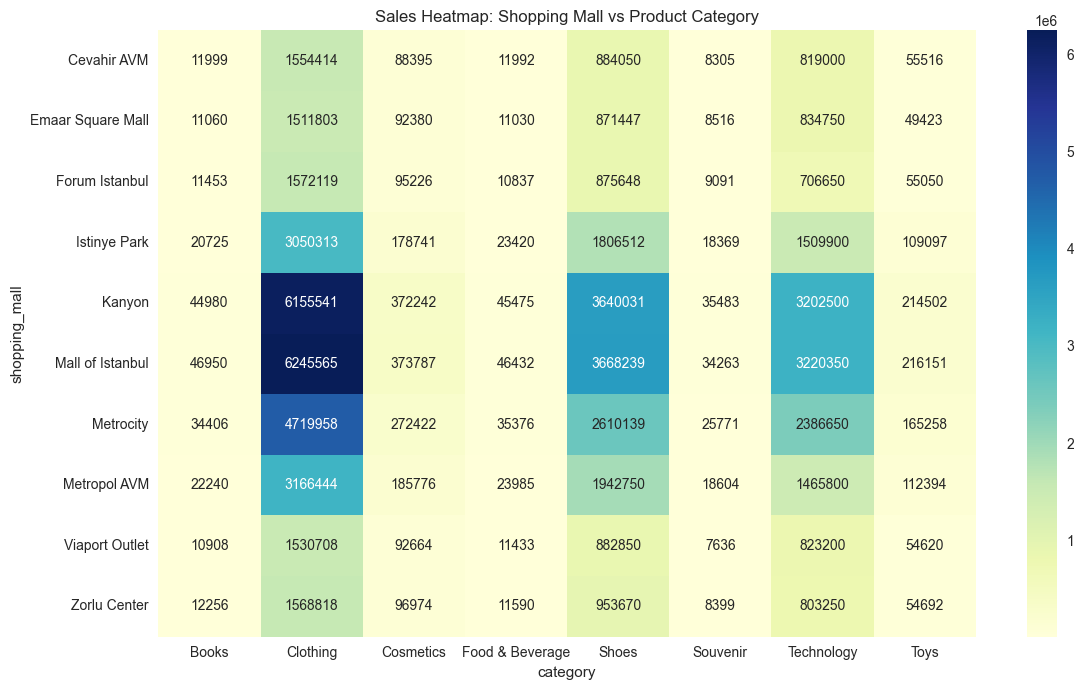

In [16]:
# Step 18: Heatmap

plt.figure(figsize=(12, 7))

sns.heatmap(
    combined_sales,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Sales Heatmap: Shopping Mall vs Product Category")
plt.tight_layout()
plt.show()

In [17]:
# Step 19: Find Top and Lowest Performing Malls

print("Top Performing Shopping Mall:")
print(region_sales.idxmax(), "-", region_sales.max())

print("\nLowest Performing Shopping Mall:")
print(region_sales.idxmin(), "-", region_sales.min())

Top Performing Shopping Mall:
Mall of Istanbul - 13851737.62

Lowest Performing Shopping Mall:
Forum Istanbul - 3336073.82


Monthly Sales:
Month
2021-01    2656422.78
2021-02    2358636.34
2021-03    2618434.14
2021-04    2558825.62
2021-05    2662369.93
2021-06    2547239.73
2021-07    2802468.58
2021-08    2632303.32
2021-09    2530305.88
2021-10    2782418.40
2021-11    2547152.35
2021-12    2619727.56
2022-01    2656149.96
2022-02    2318201.08
2022-03    2705190.76
2022-04    2543653.14
2022-05    2684556.89
2022-06    2613106.01
2022-07    2749554.99
2022-08    2638238.71
2022-09    2584908.39
2022-10    2755839.69
2022-11    2447988.76
2022-12    2675437.80
2023-01    2620053.89
2023-02    2558459.90
2023-03     683721.31
Freq: M, Name: TotalSales, dtype: float64


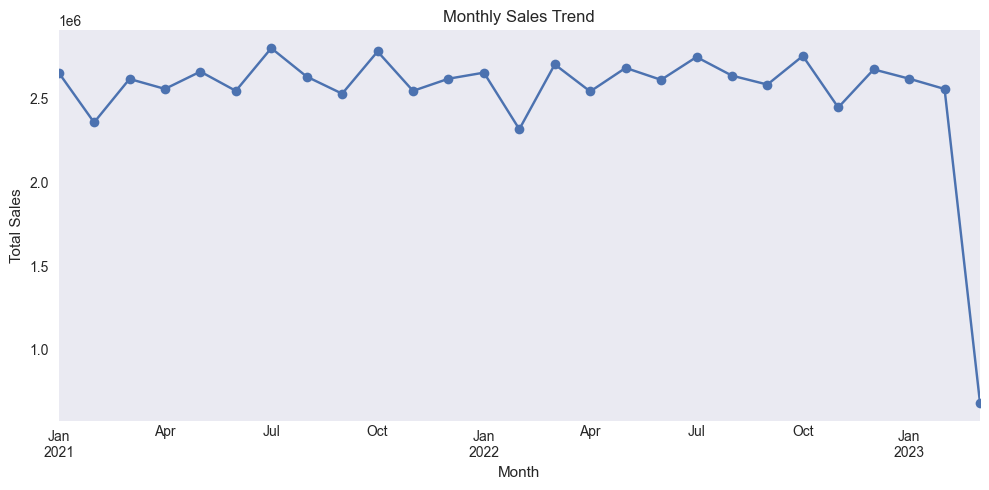

In [18]:
# Step 20: Monthly Sales Trend

# Convert invoice_date into datetime format
df['invoice_date'] = pd.to_datetime(
    df['invoice_date'],
    dayfirst=True,
    errors='coerce'
)

# Remove records with invalid dates for time analysis
date_df = df.dropna(subset=['invoice_date']).copy()

# Extract month
date_df['Month'] = date_df['invoice_date'].dt.to_period('M')

# Calculate monthly sales
monthly_sales = date_df.groupby('Month')['TotalSales'].sum()

print("Monthly Sales:")
print(monthly_sales)

# Plot monthly sales
monthly_sales.plot(
    kind='line',
    marker='o',
    figsize=(10, 5)
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid()
plt.tight_layout()
plt.show()

Monthly Sales Growth Rate (%):
Month
2021-01          NaN
2021-02   -11.210054
2021-03    11.014746
2021-04    -2.276495
2021-05     4.046556
2021-06    -4.324350
2021-07    10.019821
2021-08    -6.071977
2021-09    -3.874836
2021-10     9.963717
2021-11    -8.455452
2021-12     2.849269
2022-01     1.390313
2022-02   -12.723261
2022-03    16.693534
2022-04    -5.971395
2022-05     5.539425
2022-06    -2.661552
2022-07     5.221716
2022-08    -4.048520
2022-09    -2.021436
2022-10     6.612664
2022-11   -11.170858
2022-12     9.291262
2023-01    -2.070088
2023-02    -2.350867
2023-03   -73.276059
Freq: M, Name: TotalSales, dtype: float64


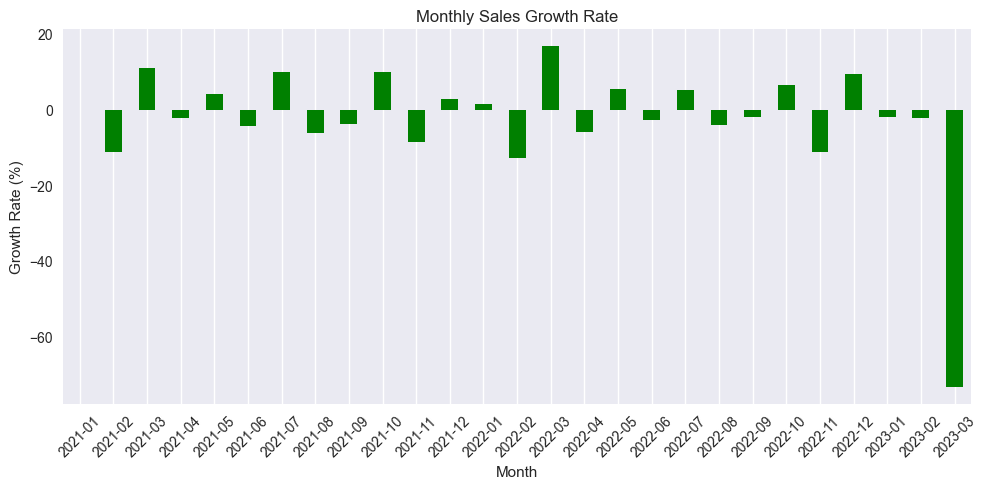

In [19]:
# Step 21: Calculate Monthly Growth Rate

growth_rate = monthly_sales.pct_change() * 100

print("Monthly Sales Growth Rate (%):")
print(growth_rate)

# Plot growth rate
growth_rate.plot(
    kind='bar',
    figsize=(10, 5),
    color='green'
)

plt.title("Monthly Sales Growth Rate")
plt.xlabel("Month")
plt.ylabel("Growth Rate (%)")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

Sales by Month of Year:
Month_Name
January      7932626.63
February     7235297.32
March        6007346.21
April        5102478.76
May          5346926.82
June         5160345.74
July         5552023.57
August       5270542.03
September    5115214.27
October      5538258.09
November     4995141.11
December     5295165.36
Name: TotalSales, dtype: float64


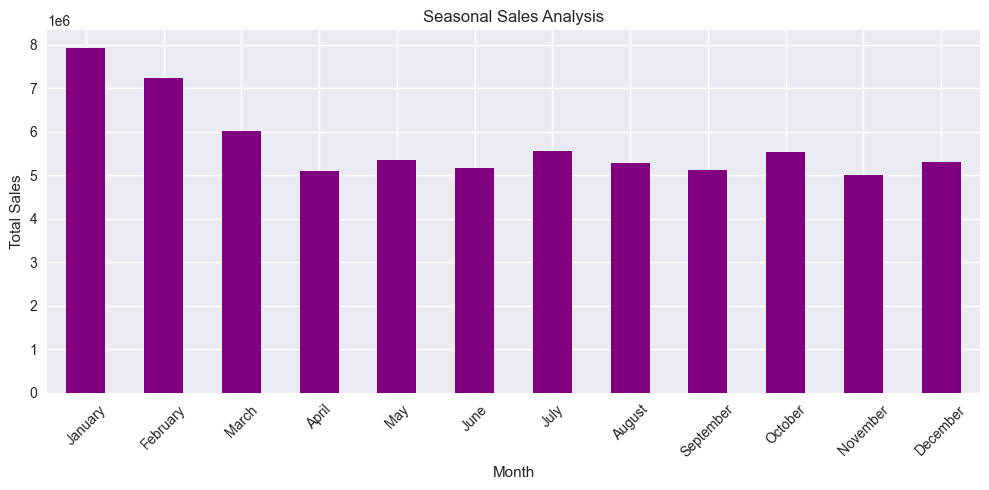

In [20]:
# Step 22: Seasonal Sales Analysis

date_df['Month_Name'] = date_df['invoice_date'].dt.month_name()

seasonal_sales = date_df.groupby('Month_Name')['TotalSales'].sum()

# Arrange months in calendar order
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

seasonal_sales = seasonal_sales.reindex(month_order).dropna()

print("Sales by Month of Year:")
print(seasonal_sales)

seasonal_sales.plot(
    kind='bar',
    figsize=(10, 5),
    color='purple'
)

plt.title("Seasonal Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
# Step 23: Business Insights

print("BUSINESS INSIGHTS")

print("\nBest Performing Shopping Mall:")
print(region_sales.idxmax())

print("\nLowest Performing Shopping Mall:")
print(region_sales.idxmin())

print("\nBest Selling Product Category:")
print(category_sales.idxmax())

print("\nLowest Selling Product Category:")
print(category_sales.idxmin())

print("\nTotal Sales:")
print(df['TotalSales'].sum())

BUSINESS INSIGHTS

Best Performing Shopping Mall:
Mall of Istanbul

Lowest Performing Shopping Mall:
Forum Istanbul

Best Selling Product Category:
Clothing

Lowest Selling Product Category:
Souvenir

Total Sales:
68551365.91


In [22]:
# Step 24: Final Result

print("SALES PERFORMANCE ANALYSIS COMPLETED SUCCESSFULLY!")

print("\nConclusion:")
print("1. Sales data was collected and cleaned.")
print("2. Sales performance was analyzed by shopping mall.")
print("3. Product category sales were compared.")
print("4. Top and lowest performing malls were identified.")
print("5. Monthly sales trends and growth rates were analyzed.")
print("6. Charts and heatmaps helped visualize sales performance.")
print("7. Business insights were generated to support better decisions.")

SALES PERFORMANCE ANALYSIS COMPLETED SUCCESSFULLY!

Conclusion:
1. Sales data was collected and cleaned.
2. Sales performance was analyzed by shopping mall.
3. Product category sales were compared.
4. Top and lowest performing malls were identified.
5. Monthly sales trends and growth rates were analyzed.
6. Charts and heatmaps helped visualize sales performance.
7. Business insights were generated to support better decisions.
